# 06 — Business Application

Applies the final model to **every customer** (Phases 8-11 of the PRD):

1. Churn risk scoring with documented thresholds
2. Estimated revenue at risk (clearly labeled estimates)
3. Business segmentation (risk x value)
4. Prioritized retention list

The dashboard-ready exports for Power BI are also produced here.

In [1]:
import sys
from pathlib import Path

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(p for p in _candidates if (p / "src").exists())
sys.path.insert(0, str(PROJECT_ROOT))
import warnings
warnings.filterwarnings("ignore")

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.models.scoring import (
    add_priority_score, add_value_tier, revenue_at_risk, score_customers,
    segment_summary, validate_scores,
)

sns.set_theme(style="whitegrid")
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "telco_features.csv")
meta = json.loads((PROJECT_ROOT / "models" / "model_metadata.json").read_text())
final_model = joblib.load(PROJECT_ROOT / "models" / "final_model.joblib")
REPORTS = PROJECT_ROOT / "reports"
DASH = PROJECT_ROOT / "dashboard"
REPORTS.mkdir(exist_ok=True)
DASH.mkdir(exist_ok=True)


## 1. Score all customers

Thresholds come from notebook 04 (out-of-fold training behaviour): HIGH >= 0.55 (F1-maximizing), MEDIUM >= 0.35 (F2-maximizing broad-capture layer).

In [2]:
scores = score_customers(df, final_model, meta['high_threshold'], meta['medium_threshold'])
checks = validate_scores(scores, df)
print('validation:', checks)
print(f'rows: {len(scores)} (dataset: {len(df)})')
scores = add_value_tier(df, scores)
print('\nrisk level distribution:')
print(scores['risk_level'].value_counts())
print('\navg probability by risk level:')
print(scores.groupby('risk_level')['churn_probability'].agg(['mean', 'min', 'max']).round(3))

validation: {'one_row_per_customer': True, 'probability_in_0_1': True, 'risk_levels_valid': True, 'no_missing': True}
rows: 7043 (dataset: 7043)

risk level distribution:
risk_level
Low       3266
High      2503
Medium    1274
Name: count, dtype: int64

avg probability by risk level:
             mean    min    max
risk_level                     
High        0.752  0.550  0.958
Low         0.154  0.024  0.350
Medium      0.445  0.350  0.549


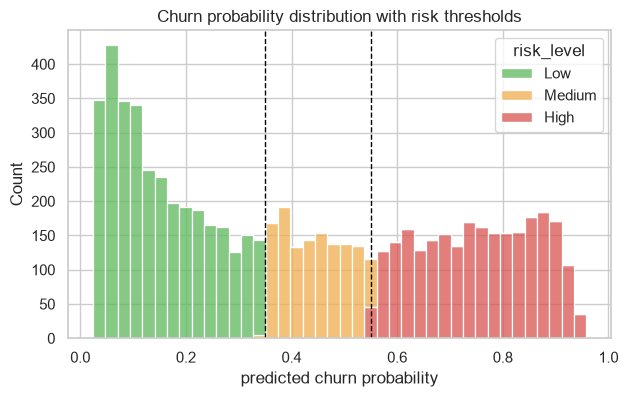

saved reports/churn_risk_scores.csv


In [3]:
scores.to_csv(REPORTS / 'churn_risk_scores.csv', index=False)
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=scores, x='churn_probability', hue='risk_level', hue_order=['Low', 'Medium', 'High'],
             bins=40, multiple='stack', palette=['#5cb85c', '#f0ad4e', '#d9534f'], ax=ax)
ax.set(title='Churn probability distribution with risk thresholds', xlabel='predicted churn probability')
for t in [meta['medium_threshold'], meta['high_threshold']]:
    ax.axvline(t, color='black', ls='--', lw=1)
fig.savefig(REPORTS / 'figures' / 'risk_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved reports/churn_risk_scores.csv')

## 2. Estimated revenue at risk

> **This is an ESTIMATE, not a prediction of actual losses.** Predicted churn is not guaranteed churn. Two views are given:
>
> - **Run-rate exposure**: total monthly revenue billed to High-risk customers — the upper bound if every one of them churned.
> - **Probability-weighted exposure**: sum of (probability x monthly charge) — the model's confidence-weighted exposure, the fairer headline number.
>
> The annualized figure simply multiplies monthly exposure by 12, i.e. it assumes one full year of billing at the current run-rate and no retention actions. Real exposure depends on retention effectiveness and churn timing.

In [4]:
rar = revenue_at_risk(scores)
for k, v in rar.items():
    print(f'{k}: {v:,.0f}' if isinstance(v, (int, float)) else f'{k}: {v}')

summary_rows = {
    'metric': ['High-risk customers', 'Monthly revenue of High-risk customers (run-rate exposure estimate, upper bound)',
               'Annualized exposure estimate (x12, assumes 1 year at current run-rate, no intervention)',
               'Probability-weighted monthly exposure (headline estimate)',
               'High-risk AND high-value (top-quartile) customers',
               'Monthly revenue of High-risk AND high-value customers (estimate)'],
    'estimate': [f"{rar['high_risk_customers']:,}", f"${rar['monthly_revenue_high_risk']:,.0f}",
                 f"${rar['annualized_exposure_high_risk_x12']:,.0f}",
                 f"${rar['probability_weighted_monthly_exposure']:,.0f}",
                 f"{rar['high_risk_high_value_customers']:,}",
                 f"${rar['monthly_revenue_high_risk_high_value']:,.0f}"],
}
import pandas as pd
pd.DataFrame(summary_rows).to_csv(REPORTS / 'revenue_at_risk_summary.csv', index=False)
print('\nsaved reports/revenue_at_risk_summary.csv')

high_risk_customers: 2,503
monthly_revenue_high_risk: 193,567
annualized_exposure_high_risk_x12: 2,322,809
probability_weighted_monthly_exposure: 146,705
high_risk_high_value_customers: 781
monthly_revenue_high_risk_high_value: 76,651

saved reports/revenue_at_risk_summary.csv


## 3. Business segments (risk x value)

Four actionable segments; the top-priority one is **High risk + High value** — the customers the retention team should contact first.

risk_level     value_tier  customers  monthly_revenue  avg_churn_probability  share_of_customers  share_of_monthly_revenue
      High     High value        781         76650.70                  0.753               0.111                     0.168
      High Standard value       1722        116916.75                  0.751               0.244                     0.256
       Low     High value        620         64536.35                  0.212               0.088                     0.141
       Low Standard value       2646        116963.20                  0.140               0.376                     0.256
    Medium     High value        357         36193.35                  0.452               0.051                     0.079
    Medium Standard value        917         44856.25                  0.443               0.130                     0.098


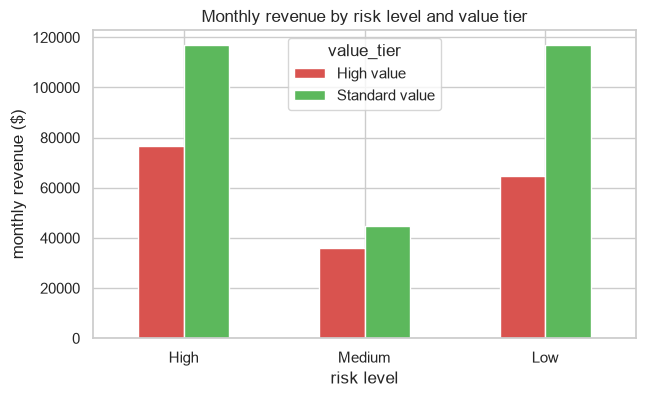

In [5]:
seg = segment_summary(scores)
print(seg.round(3).to_string(index=False))
seg.to_csv(REPORTS / 'business_segments.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
seg_pivot = scores.pivot_table(index='risk_level', columns='value_tier', values='MonthlyCharges', aggfunc='sum')
seg_pivot = seg_pivot.reindex(['High', 'Medium', 'Low']).reindex(columns=['High value', 'Standard value'])
seg_pivot.plot(kind='bar', ax=ax, color=['#d9534f', '#5cb85c'])
ax.set(title='Monthly revenue by risk level and value tier', ylabel='monthly revenue ($)', xlabel='risk level')
plt.xticks(rotation=0)
fig.savefig(REPORTS / 'figures' / 'revenue_by_segment.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Who should we contact first? — retention prioritization

**Methodology:** priority score = churn probability x monthly revenue (expected monthly revenue exposure). Sorting by probability alone would surface cheap customers; sorting by revenue alone would surface safe ones. The product targets the customers whose expected loss is largest. Ties in business practice are broken by the high-value/high-risk segment; the score is a ranking tool, not a financial forecast.

In [6]:
priority = add_priority_score(scores)
priority_out = priority[['customerID', 'churn_probability', 'risk_level', 'MonthlyCharges', 'value_tier', 'priority_score']].copy()
priority_out.to_csv(REPORTS / 'retention_priority_list.csv', index=False)

print('Top 20 retention priorities:')
print(priority_out.head(20).round(3).to_string(index=False))
print('\nTop 200 priorities: monthly revenue covered =', f"${priority.head(200)['MonthlyCharges'].sum():,.0f}")

high_value_high_risk = priority[(priority['risk_level'] == 'High') & (priority['value_tier'] == 'High value')]
hvhr = high_value_high_risk[['customerID', 'churn_probability', 'risk_level', 'MonthlyCharges', 'value_tier', 'priority_score']]
hvhr.to_csv(REPORTS / 'high_value_high_risk_customers.csv', index=False)
print(f'\nhigh-risk + high-value list saved: {len(hvhr)} customers, ${hvhr["MonthlyCharges"].sum():,.0f}/mo')

Top 20 retention priorities:
customerID  churn_probability risk_level  MonthlyCharges value_tier  priority_score
1400-MMYXY              0.943       High          105.90 High value          99.862
6496-SLWHQ              0.938       High          105.00 High value          98.485
1875-QIVME              0.924       High          104.40 High value          96.476
4587-VVTOX              0.914       High          105.30 High value          96.264
7216-EWTRS              0.948       High          100.80 High value          95.607
5419-JPRRN              0.941       High          101.45 High value          95.486
3292-PBZEJ              0.857       High          111.40 High value          95.462
2081-VEYEH              0.884       High          107.95 High value          95.405
6734-GMPVK              0.905       High          105.30 High value          95.245
6023-YEBUP              0.942       High          100.95 High value          95.058
5760-IFJOZ              0.878       High       

## 5. Profile of the high-risk population

What actually characterizes High-risk customers? (Model-based; associations, not causes.)

In [7]:
high = scores[scores['risk_level'] == 'High'].index
df_high = df.loc[scores.loc[high, 'customerID'].index]

profile = {}
for col in ['Contract', 'PaymentMethod', 'InternetService', 'tenure_band', 'OnlineSecurity']:
    t = df_high[col].value_counts(normalize=True).round(3) * 100
    profile[col] = t
for col, t in profile.items():
    print(f'\n{col} (share of {len(df_high):,} High-risk customers):')
    print(t.to_string())


Contract (share of 2,503 High-risk customers):
Contract
Month-to-month    97.8
One year           2.2
Two year           0.0

PaymentMethod (share of 2,503 High-risk customers):
PaymentMethod
Electronic check             63.8
Mailed check                 14.6
Bank transfer (automatic)    11.1
Credit card (automatic)      10.5

InternetService (share of 2,503 High-risk customers):
InternetService
Fiber optic    76.0
DSL            23.9
No              0.1

tenure_band (share of 2,503 High-risk customers):
tenure_band
0-6 mo      42.7
13-24 mo    18.7
25-48 mo    18.1
7-12 mo     15.0
49-72 mo     5.4

OnlineSecurity (share of 2,503 High-risk customers):
OnlineSecurity
No                     88.3
Yes                    11.6
No internet service     0.1


In [8]:
# Dashboard-ready exports (Phase 12)
report = df.merge(scores[['customerID', 'churn_probability', 'risk_level', 'value_tier']], on='customerID')

report[['customerID', 'Contract', 'tenure', 'PaymentMethod', 'InternetService', 'MonthlyCharges', 'TotalCharges',
        'Churn', 'churn_probability', 'risk_level', 'value_tier']].to_csv(DASH / 'risk_scores.csv', index=False)

kpis = {
    'kpi': ['total_customers', 'churn_rate_pct', 'total_monthly_revenue', 'avg_monthly_charges',
            'high_risk_customers', 'estimated_monthly_revenue_at_risk',
            'estimated_annualized_revenue_at_risk'],
    'value': [len(df), round(100 * (df['Churn'] == 'Yes').mean(), 2),
              round(df['MonthlyCharges'].sum(), 2), round(df['MonthlyCharges'].mean(), 2),
              rar['high_risk_customers'], round(rar['probability_weighted_monthly_exposure'], 2),
              round(rar['probability_weighted_monthly_exposure'] * 12, 2)],
}
pd.DataFrame(kpis).to_csv(DASH / 'kpi_summary.csv', index=False)

for col, fname in [('Contract', 'churn_by_contract.csv'), ('tenure_band', 'churn_by_tenure_band.csv'),
                   ('PaymentMethod', 'churn_by_payment.csv'), ('InternetService', 'churn_by_internet.csv')]:
    t = report.groupby(col).agg(customers=('customerID', 'count'),
                                churners=('Churn', lambda s: (s == 'Yes').sum()),
                                monthly_revenue=('MonthlyCharges', 'sum'))
    t['churn_rate_pct'] = (100 * t['churners'] / t['customers']).round(2)
    t.to_csv(DASH / fname)

seg_export = seg.copy()
seg_export.to_csv(DASH / 'business_segments.csv', index=False)
priority_out.head(200).to_csv(DASH / 'retention_priority_top200.csv', index=False)

features = pd.read_csv(REPORTS / 'top_model_features.csv')
features.head(15).to_csv(DASH / 'top_model_features.csv', index=False)

print('dashboard exports:', sorted(p.name for p in DASH.glob('*.csv')))

dashboard exports: ['business_segments.csv', 'churn_by_contract.csv', 'churn_by_internet.csv', 'churn_by_payment.csv', 'churn_by_tenure_band.csv', 'kpi_summary.csv', 'retention_priority_top200.csv', 'risk_scores.csv', 'top_model_features.csv']


## Summary of decisions in this phase

- **Risk thresholds:** inherited from notebook 04 (HIGH=0.55 F1-max; MEDIUM=0.35 F2-max) — documented and reproducible.
- **Value definition:** top quartile of `MonthlyCharges` (current revenue run-rate). Alternative (historical `TotalCharges`) rejected because forward-looking exposure matters for retention.
- **Priority score:** probability x monthly revenue, because retention capacity is finite and expected loss — not raw probability — is what the team should rank on.
- **Revenue at risk** is reported as two estimates (run-rate upper bound and probability-weighted headline) with assumptions stated; predicted churn is never equated to lost revenue.